In [182]:
import pandas as pd
from utils import merge_csv_files_in_directory, standardize_labels
from IPython.display import display, HTML

df = pd.read_csv("merged.csv")
# df = merge_csv_files_in_directory()

#remove duplicates
df = df.drop_duplicates(keep='first')

df.drop("pr_title",inplace = True,axis=1)
df.drop("class_names",inplace = True,axis=1)
df.drop("commit_sha",inplace = True,axis=1)
df.drop("commit_message",inplace = True,axis=1)
df.drop("file_path",inplace = True,axis=1)
df.drop("additions",inplace = True,axis=1)
df.drop("deletions",inplace = True,axis=1)
df.drop("file_name",inplace = True,axis=1)
df.drop("full_repo_name",inplace = True,axis=1)

df.drop("content_before",inplace = True,axis=1)
df.drop("content_after",inplace = True,axis=1)

# df.drop("patch",inplace = True,axis=1)

df.drop("created_at",inplace = True,axis=1)
df.drop("closed_at",inplace = True,axis=1)
df.drop("status",inplace = True,axis=1)

# Standardize labels
labels = ['bug', 'enhancement', 'performance', 'refactor', 'clean']
df = standardize_labels(df, labels)
resulting_label_count = df['labels'].nunique()

### Limit df size for testing purposes ###
label_enh = df[df['labels'] == 'enhancement']
label_bug = df[df['labels'] == 'bug']
label_cln = df[df['labels'] == 'clean']
# label_prf = df[df['labels'] == 'performance']
# label_ref = df[df['labels'] == 'refactor']
sampled_enh = label_enh.sample(n=15300, random_state=1)
sampled_bug = label_bug.sample(n=15300, random_state=1)
sampled_cln = label_cln.sample(n=15300, random_state=1)
# sampled_prf = label_prf.sample(n=3200, random_state=1)
# sampled_ref = label_ref.sample(n=3200, random_state=1)
df = pd.concat([sampled_enh, sampled_bug, sampled_cln])

# # Filter NaN rows
# df = df.dropna(subset=['content_before', 'content_after'])
df = df.dropna(subset=['patch'])

# Display DataFrame with a scrollable table
#display(HTML(df.to_html(max_rows=None, max_cols=None)))

# Count the occurrences of each unique value in the 'lables' column
label_counts = df['labels'].value_counts()
print(label_counts)

df

labels
enhancement    15300
bug            15300
clean          15300
Name: count, dtype: int64


,labels,patch
45542,enhancement,"@@ -103,10 +103,27 @@ public MutableRoaringBit..."
17784,enhancement,"@@ -62,7 +62,7 @@ public TraceBrief queryBasic..."
45192,enhancement,"@@ -25,6 +25,7 @@\n import java.util.HashMap;\..."
54149,enhancement,"@@ -453,7 +453,7 @@ public static void main(St..."
47560,enhancement,"@@ -17,64 +17,69 @@\n \n package opennlp.tools..."
...,...,...
28870,clean,"@@ -245,6 +245,7 @@ void unsetSuccessAndSendWr..."
30713,clean,"@@ -36,7 +36,6 @@\n import org.eclipse.persist..."
24323,clean,"@@ -18,30 +18,29 @@\n */\n package org.apache..."
32419,clean,"@@ -77,7 +77,7 @@ public void initialize(Templ..."


In [183]:
from transformers import AutoTokenizer, AutoModel
import torch

tokenizer = AutoTokenizer.from_pretrained("microsoft/codebert-base")
model = AutoModel.from_pretrained("microsoft/codebert-base").to("cuda:0")

In [184]:
import os

# Directory to save embeddings
save_dir = "embeddings/pooler_embeddings_patch_before_largewithcodedata_15300limit3label"
os.makedirs(save_dir, exist_ok=True)

In [185]:
from utils import extract_code_from_patch

# Tokenizing using subtracting full code before and after embeddings

# def generate_and_save_embeddings_batch(contents_before, contents_after, indices):
def generate_and_save_embeddings_batch(patches, indices):
    patches_before = []

    for patch in patches:
        patch_before, patch_after = extract_code_from_patch(patch)
        patches_before.append(patch_before)
    
    
    # Tokenize the before and after code patch snippet
    tokens_before = tokenizer(patches_before, truncation=True, padding='max_length', max_length=512, return_tensors='pt').to("cuda:0")

    # Tokenize the before and after code snippets
    # tokens_before = tokenizer(list(contents_before), truncation=True, padding='max_length', max_length=512, return_tensors='pt').to("cuda:0")
    # tokens_after = tokenizer(list(contents_after), truncation=True, padding='max_length', max_length=512, return_tensors='pt').to("cuda:0")

    # Get the embeddings for both tokenized sequences
    with torch.no_grad():

        embeddings_before = model(**tokens_before).pooler_output #pooler
        # embeddings_after = model(**tokens_after).pooler_output
    
    # Subtract the embeddings
    # subtracted_embeddings = embeddings_after - embeddings_before
    # print(subtracted_embeddings.shape)
    
    # Average the subtracted embeddings across the token dimension
    # subtracted_embeddings = subtracted_embeddings.mean(dim=1)
    
    save_path = os.path.join(save_dir, f"embedding_{indices[0].item()}.pt")
    torch.save(embeddings_before, save_path)
    

In [186]:
from torch.utils.data import DataLoader, Dataset

# Custom Dataset Class to handle the dataframe
class CodeDataset(Dataset):
    def __init__(self, df):
        self.df = df

    def __len__(self):
        return len(self.df)
    
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        # content_before = row['content_before']
        # content_after = row['content_after']
        # return content_before, content_after, idx
        
        patch = row['patch']
        return patch, idx

In [187]:
import tqdm

# Creating a DataLoader
def create_dataloader(dataframe, batch_size=32, shuffle=False):
    dataset = CodeDataset(dataframe)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)

batch_size = 128
dataloader = create_dataloader(df, batch_size=batch_size)

for batch in tqdm.notebook.tqdm(dataloader):
    
    # contents_before, contents_after, indices = batch
    # generate_and_save_embeddings_batch(contents_before, contents_after, indices)
    
    patch, indices = batch
    generate_and_save_embeddings_batch(patch, indices)
    


  0%|          | 0/359 [00:00<?, ?it/s]

In [196]:
## Alternate starting node, if embeddings will be loaded
import pandas as pd
from utils import merge_csv_files_in_directory, standardize_labels
from IPython.display import display, HTML
from utils import load_embeddings_from_directory, merge_csv_files_in_directory, standardize_labels

df = pd.read_csv("merged.csv")
# df = merge_csv_files_in_directory()

#remove duplicates
df = df.drop_duplicates(keep='first')

df.drop("pr_title",inplace = True,axis=1)
df.drop("class_names",inplace = True,axis=1)
df.drop("commit_sha",inplace = True,axis=1)
df.drop("commit_message",inplace = True,axis=1)
df.drop("file_path",inplace = True,axis=1)
df.drop("additions",inplace = True,axis=1)
df.drop("deletions",inplace = True,axis=1)
df.drop("file_name",inplace = True,axis=1)
df.drop("full_repo_name",inplace = True,axis=1)

df.drop("content_before",inplace = True,axis=1)
df.drop("content_after",inplace = True,axis=1)

# df.drop("patch",inplace = True,axis=1)

df.drop("created_at",inplace = True,axis=1)
df.drop("closed_at",inplace = True,axis=1)
df.drop("status",inplace = True,axis=1)

# Standardize labels
labels = ['bug', 'enhancement', 'performance', 'refactor', 'clean']
df = standardize_labels(df, labels)
resulting_label_count = df['labels'].nunique()

# Count the occurrences of each unique value in the 'lables' column
label_counts = df['labels'].value_counts()
print(label_counts)

### Limit df size for testing purposes ###
label_enh = df[df['labels'] == 'enhancement']
label_bug = df[df['labels'] == 'bug']
label_cln = df[df['labels'] == 'clean']
# label_prf = df[df['labels'] == 'performance']
# label_ref = df[df['labels'] == 'refactor']
sampled_enh = label_enh.sample(n=15300, random_state=1)
sampled_bug = label_bug.sample(n=15300, random_state=1)
sampled_cln = label_cln.sample(n=15300, random_state=1)
# sampled_prf = label_prf.sample(n=3200, random_state=1)
# sampled_ref = label_ref.sample(n=3200, random_state=1)
df = pd.concat([sampled_enh, sampled_bug, sampled_cln])

# Refreshing label count
resulting_label_count = df['labels'].nunique()

# # Filter NaN rows
# df = df.dropna(subset=['content_before', 'content_after'])
df = df.dropna(subset=['patch'])

# Display DataFrame with a scrollable table
#display(HTML(df.to_html(max_rows=None, max_cols=None)))

# Count the occurrences of each unique value in the 'lables' column
label_counts = df['labels'].value_counts()
print(label_counts)

df

labels
bug            17065
enhancement    15764
clean          15336
performance     5043
refactor        3217
Name: count, dtype: int64
labels
enhancement    15300
bug            15300
clean          15300
Name: count, dtype: int64


,labels,patch
45542,enhancement,"@@ -103,10 +103,27 @@ public MutableRoaringBit..."
17784,enhancement,"@@ -62,7 +62,7 @@ public TraceBrief queryBasic..."
45192,enhancement,"@@ -25,6 +25,7 @@\n import java.util.HashMap;\..."
54149,enhancement,"@@ -453,7 +453,7 @@ public static void main(St..."
47560,enhancement,"@@ -17,64 +17,69 @@\n \n package opennlp.tools..."
...,...,...
28870,clean,"@@ -245,6 +245,7 @@ void unsetSuccessAndSendWr..."
30713,clean,"@@ -36,7 +36,6 @@\n import org.eclipse.persist..."
24323,clean,"@@ -18,30 +18,29 @@\n */\n package org.apache..."
32419,clean,"@@ -77,7 +77,7 @@ public void initialize(Templ..."


In [197]:
# # Load embeddings from embeddings folder
all_embeddings = load_embeddings_from_directory('embeddings/pooler_embeddings_patch_before_largewithcodedata_15300limit3label')

# Convert the embeddings to a DataFrame or add them to the original DataFrame
df['tokens'] = list(torch.chunk(torch.vstack(all_embeddings).cpu(), df.shape[0], dim=0))
df

  0%|          | 0/359 [00:00<?, ?it/s]

embedding_0.pt
embedding_128.pt
embedding_256.pt
embedding_384.pt
embedding_512.pt
embedding_640.pt
embedding_768.pt
embedding_896.pt
embedding_1024.pt
embedding_1152.pt
embedding_1280.pt
embedding_1408.pt
embedding_1536.pt
embedding_1664.pt
embedding_1792.pt
embedding_1920.pt
embedding_2048.pt
embedding_2176.pt
embedding_2304.pt
embedding_2432.pt
embedding_2560.pt
embedding_2688.pt
embedding_2816.pt
embedding_2944.pt
embedding_3072.pt
embedding_3200.pt
embedding_3328.pt
embedding_3456.pt
embedding_3584.pt
embedding_3712.pt
embedding_3840.pt
embedding_3968.pt
embedding_4096.pt
embedding_4224.pt
embedding_4352.pt
embedding_4480.pt
embedding_4608.pt
embedding_4736.pt
embedding_4864.pt
embedding_4992.pt
embedding_5120.pt
embedding_5248.pt
embedding_5376.pt
embedding_5504.pt
embedding_5632.pt
embedding_5760.pt
embedding_5888.pt
embedding_6016.pt
embedding_6144.pt
embedding_6272.pt
embedding_6400.pt
embedding_6528.pt
embedding_6656.pt
embedding_6784.pt
embedding_6912.pt
embedding_7040.pt
em

,labels,patch,tokens
45542,enhancement,"@@ -103,10 +103,27 @@ public MutableRoaringBit...","[[tensor(0.5337), tensor(-0.5748), tensor(-0.6..."
17784,enhancement,"@@ -62,7 +62,7 @@ public TraceBrief queryBasic...","[[tensor(0.5697), tensor(-0.5170), tensor(-0.6..."
45192,enhancement,"@@ -25,6 +25,7 @@\n import java.util.HashMap;\...","[[tensor(0.5091), tensor(-0.5754), tensor(-0.7..."
54149,enhancement,"@@ -453,7 +453,7 @@ public static void main(St...","[[tensor(0.4519), tensor(-0.5356), tensor(-0.6..."
47560,enhancement,"@@ -17,64 +17,69 @@\n \n package opennlp.tools...","[[tensor(0.4495), tensor(-0.5512), tensor(-0.6..."
...,...,...,...
28870,clean,"@@ -245,6 +245,7 @@ void unsetSuccessAndSendWr...","[[tensor(0.5114), tensor(-0.5558), tensor(-0.6..."
30713,clean,"@@ -36,7 +36,6 @@\n import org.eclipse.persist...","[[tensor(0.5172), tensor(-0.5515), tensor(-0.7..."
24323,clean,"@@ -18,30 +18,29 @@\n */\n package org.apache...","[[tensor(0.5046), tensor(-0.5942), tensor(-0.7..."
32419,clean,"@@ -77,7 +77,7 @@ public void initialize(Templ...","[[tensor(0.4843), tensor(-0.5568), tensor(-0.6..."


In [198]:
# # Tokenizing using patch
# import torch
# from utils import extract_code_from_patch

# def tokenize_code(row):

#     patch_before, patch_after = extract_code_from_patch(row['patch'])
    
#     # Tokenize the before and after code snippets
#     tokens_before = tokenizer(patch_before, truncation=True, padding='max_length', max_length=512, return_tensors='pt')
#     tokens_after = tokenizer(patch_after, truncation=True, padding='max_length', max_length=512, return_tensors='pt')
    
#     # Get the embeddings for both tokenized sequences
#     with torch.no_grad():
#         embeddings_before = model(**tokens_before).last_hidden_state
#         embeddings_after = model(**tokens_after).last_hidden_state
    
#     # Ensure the two tensors are of the same shape before subtracting
#     assert embeddings_before.shape == embeddings_after.shape, "Shape mismatch between before and after embeddings"
    
#     # Subtract the embeddings
#     subtracted_embeddings = embeddings_after - embeddings_before
    
#     # Average the subtracted embeddings across the token dimension
#     # to get a single vector representation for each input. (2D tensor instead of 3D)
#     subtracted_embeddings = subtracted_embeddings.mean(dim=1)
    
#     return subtracted_embeddings

# df['tokens'] = df.apply(tokenize_code, axis=1)
# df

In [220]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression # Classification
from sklearn.multioutput import MultiOutputClassifier
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score
import pandas as pd
import torch

# One-hot encoding ile labels sütununu dönüştürme
df_encoded = pd.get_dummies(df, columns=['labels'])

# Özellikler ve etiketler
X = torch.stack(tuple(df['tokens'].values))
# y = df_encoded.drop(columns=['content_before', 'content_after', 'tokens'])
y = df_encoded.drop(columns=['patch', 'tokens'])
y = y.astype(int) # convert it 0,1     instead of true, false 

# Eğitim ve test setlerine bölme
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42) #random_state: 0,3074,42

# Next, split the test data into test and validation sets
X_test, X_val, y_test, y_val = train_test_split(X_test, y_test, test_size=0.5, random_state=42)

y_test

,labels_bug,labels_clean,labels_enhancement
57451,1,0,0
25847,0,1,0
51334,1,0,0
16197,1,0,0
15816,1,0,0
...,...,...,...
53988,0,0,1
54066,0,0,1
50841,0,0,1
31691,0,1,0


In [221]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Flattening the 3D tensor to 2D
X_train = X_train.view(X_train.size(0), -1) 
X_test = X_test.view(X_test.size(0), -1)  
X_val = X_val.view(X_val.size(0), -1)

# # Scaling X values so that the mean is 0 and the st.dev. is 1
# scaler = StandardScaler()
# X_train_scaled = scaler.fit_transform(X_train)
# X_test_scaled = scaler.transform(X_test)

# # Converting inputs back to tensors
# X_train = torch.tensor(X_train_scaled, dtype=torch.float32)
# X_test = torch.tensor(X_test_scaled, dtype=torch.float32)

# Turning y into tensors
y_train = torch.tensor(y_train.to_numpy(), dtype=torch.float32)
y_test = torch.tensor(y_test.to_numpy(), dtype=torch.float32)
y_val = torch.tensor(y_val.to_numpy(), dtype=torch.float32)

print(y_train.shape)
print(X_train.shape)

torch.Size([32130, 3])
torch.Size([32130, 768])


In [222]:
# Create DataLoader
batch_size = 128
train_dataset = TensorDataset(X_train, y_train)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

In [223]:
import torch.nn as nn

# Define the ANN model
class CodeDiffNN(nn.Module):
    def __init__(self, input_size, hidden_sizes, output_size, dropout_rate=0.01):
        super(CodeDiffNN, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_sizes[0])
        self.relu1 = nn.ReLU()
        self.dropout1 = nn.Dropout(dropout_rate)  # Dropout layer after first hidden layer
        
        self.fc2 = nn.Linear(hidden_sizes[0], hidden_sizes[1])
        self.relu2 = nn.ReLU()
        self.dropout2 = nn.Dropout(dropout_rate)  # Dropout layer after second hidden layer
        
        self.fc3 = nn.Linear(hidden_sizes[1], hidden_sizes[2])
        self.relu3 = nn.ReLU()
        
        self.fc4 = nn.Linear(hidden_sizes[2], output_size)
        
    def forward(self, x):
        x = self.fc1(x)
        x = self.relu1(x)
        x = self.dropout1(x) 
        
        x = self.fc2(x)
        x = self.relu2(x)
        x = self.dropout2(x) 
        
        x = self.fc3(x)
        x = self.relu3(x) 
        
        x = self.fc4(x)
        return x


In [230]:
# Define model parameters
print(X_train.shape)
print(resulting_label_count)
input_size = X_train.shape[1]
hidden_sizes = [512, 256, 128]
output_size = resulting_label_count

device = "cuda:0"
model = CodeDiffNN(input_size, hidden_sizes, output_size).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-5)

torch.Size([32130, 768])
3


In [231]:
import copy

# Function to calculate accuracy
def calculate_accuracy(outputs, labels):
    _, predicted = torch.max(outputs, 1)  # Get the index of the max log-probability
    labels_1d = torch.argmax(labels, dim=1) # turn into 1D tensor
    correct = (predicted == labels_1d).sum().item()
    accuracy = correct / labels.size(0)  # Accuracy = number of correct predictions / total number of samples
    return accuracy


# Train the model

# Initialize variables to track the best model and best accuracy
best_accuracy = 0.0
best_model = None

# Send validation data to GPU
y_val = y_val.to(device)
X_val = X_val.to(device)

num_epochs = 500
for epoch in range(num_epochs):
    model.train()  # Set the model to training mode
    running_loss = 0.0
    running_accuracy = 0.0
    
    for batch_X, batch_y in train_loader:
        # Zero the parameter gradients
        optimizer.zero_grad()
    
        # Forward pass
        batch_y = batch_y.to(device)
        batch_X = batch_X.to(device)
        
        outputs = model(batch_X)
        loss = criterion(outputs, batch_y)
    
        # Backward pass and optimization
        loss.backward()
        optimizer.step()
        
        # Calculate accuracy
        accuracy = calculate_accuracy(outputs, batch_y)
        
        # Update running loss and accuracy
        running_loss += loss.item()
        running_accuracy += accuracy
    
    # Print average loss and accuracy for the epoch
    avg_loss = running_loss / len(train_loader)
    avg_accuracy = running_accuracy / len(train_loader)
    print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {avg_loss:.4f}, Accuracy: {avg_accuracy:.4f}')

    # Evaluate on validation data
    model.eval()  # Set the model to evaluation mode
    with torch.no_grad():  # Disable gradient computation for validation
        val_outputs = model(X_val)
        val_loss = criterion(val_outputs, y_val)
        val_accuracy = calculate_accuracy(val_outputs, y_val)
    
    print(f'Validation Loss: {val_loss:.4f}, Validation Accuracy: {val_accuracy:.4f}')
    
    # Check if the current model has the best validation accuracy
    if val_accuracy > best_accuracy:
        best_accuracy = val_accuracy
        best_model = copy.deepcopy(model.state_dict())  # Save the model with the best accuracy


Epoch [1/500], Loss: 1.0944, Accuracy: 0.3788
Validation Loss: 1.0883, Validation Accuracy: 0.4179
Epoch [2/500], Loss: 1.0783, Accuracy: 0.4207
Validation Loss: 1.0669, Validation Accuracy: 0.4221
Epoch [3/500], Loss: 1.0515, Accuracy: 0.4375
Validation Loss: 1.0353, Validation Accuracy: 0.4481
Epoch [4/500], Loss: 1.0192, Accuracy: 0.4674
Validation Loss: 1.0017, Validation Accuracy: 0.4935
Epoch [5/500], Loss: 0.9810, Accuracy: 0.5036
Validation Loss: 0.9609, Validation Accuracy: 0.5027
Epoch [6/500], Loss: 0.9484, Accuracy: 0.5219
Validation Loss: 0.9324, Validation Accuracy: 0.5386
Epoch [7/500], Loss: 0.9246, Accuracy: 0.5348
Validation Loss: 0.9145, Validation Accuracy: 0.5354
Epoch [8/500], Loss: 0.9118, Accuracy: 0.5410
Validation Loss: 0.9050, Validation Accuracy: 0.5457
Epoch [9/500], Loss: 0.9020, Accuracy: 0.5428
Validation Loss: 0.8989, Validation Accuracy: 0.5390
Epoch [10/500], Loss: 0.8961, Accuracy: 0.5507
Validation Loss: 0.8904, Validation Accuracy: 0.5451
Epoch [11

In [232]:
with torch.no_grad():
    # Load best model from previous training cycle
    model.load_state_dict(best_model)
    print(f'Best model accuracy on validation data: {best_accuracy:.4f}')

    model.eval()
    test_outputs = model(X_test.to("cuda:0"))
    
    accuracy = calculate_accuracy(test_outputs, y_test.to("cuda:0"))
    print(f'Accuracy on test data: {accuracy:.4f}')

Best model accuracy on validation data: 0.7018
Accuracy on test data: 0.6996


In [ ]:
temp_df = pd.read_csv("merged.csv")

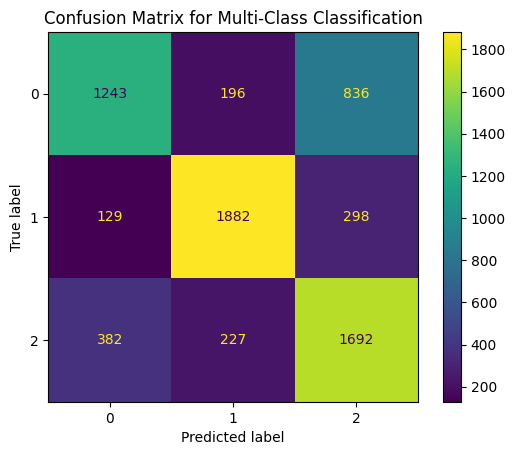

In [233]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

_, predicted = torch.max(test_outputs.detach().cpu(), 1)  # Get the index of the max log-probability
labels_1d = torch.argmax(y_test.detach().cpu(), dim=1) # turn into 1D tensor

# Convert to numpy arrays
y_test_np = labels_1d.numpy()
predicted_np = predicted.numpy()

# Compute confusion matrix
cm = confusion_matrix(y_test_np, predicted_np)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.title('Confusion Matrix for Multi-Class Classification')
plt.show()

In [ ]:
outputs.shape

In [ ]:
### DEPRECATED ###

In [ ]:

# # Örnek tahminler
# sample_data = pd.DataFrame({
#     'file_name': ['ProtoSubject.java','BasicAnnotationProcessor.java'], #1:enhancement, 2:enhancement
#     'full_repo_name': ['google/truth','google/auto']
# })

# # Kodlama işlemleri
# sample_data['file_name_encoded'] = le_class.transform(sample_data['file_name'])
# sample_data['full_repo_name_encoded'] = le_repo.transform(sample_data['full_repo_name'])

# # Özellikleri hazırlama
# X_sample = sample_data[['file_name_encoded', 'full_repo_name_encoded']]
# X_sample = torch.tensor(X_sample.to_numpy(), dtype=torch.float32)

# with torch.no_grad():
#     model.eval()
#     test_outputs = model(X_sample)
#     predicted = torch.sigmoid(test_outputs)  # Sigmoid fonksiyonu uygulanmalı
#     print( predicted)
#     predicted = (predicted > 0.5).float()  # 0.5'ten büyük olanlar 1, diğerleri 0
#     print("after ceiling")
#     print( predicted)